# 02 · Feature engineering

The EDA findings become features in `src/credit_risk/features.py::add_features`. That function is the **first step of the model pipeline**, so the same code runs in training, the API and batch scoring (no training/serving skew). It is row-wise and stateless.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
from credit_risk import load_config
from credit_risk.ingestion import make_splits

sns.set_theme(style="whitegrid", palette="deep"); pd.set_option("display.float_format", "{:.4f}".format)
cfg = load_config(); TARGET = cfg["data"]["target"]
splits = make_splits(cfg)
train = splits.train  # analysis on the training split only: the test split stays untouched
print(f"train {len(train):,} | val {len(splits.val):,} | test {len(splits.test):,} | columns {train.shape[1]}")
from credit_risk.features import ENGINEERED_FEATURES, add_features
pd.DataFrame(ENGINEERED_FEATURES.items(), columns=['feature', 'definition'])

train 196,806 | val 49,202 | test 61,503 | columns 122


,feature,definition
0,DAYS_EMPLOYED_ANOMALY,1 if DAYS_EMPLOYED carried the 365243 'not emp...
1,EMPLOYED_YEARS,Years in current employment
2,AGE_YEARS,Applicant age in years
3,EMPLOYED_TO_AGE,Share of life spent in current employment
4,CREDIT_TO_INCOME,Loan amount / annual income
5,ANNUITY_TO_INCOME,Annual repayment / annual income (debt-service...
6,ANNUITY_TO_CREDIT,Annual repayment / loan amount (inverse ~ term...
7,GOODS_TO_CREDIT,Goods price / loan amount (loan-to-value proxy)
8,INCOME_PER_PERSON,Income / family members
9,EXT_SOURCE_MEAN,Mean of available external bureau scores


## 1. Predictive power: engineered vs raw

In [2]:
def univariate_gini(df, cols):
    out = []
    for c in cols:
        s = df[c]
        if s.notna().sum() < 1000 or s.nunique() < 2:
            continue
        auc = roc_auc_score(df.loc[s.notna(), TARGET], s.dropna())
        out.append({"feature": c, "gini": abs(2 * auc - 1), "direction": "+" if auc > 0.5 else "-",
                    "missing": s.isna().mean()})
    return pd.DataFrame(out).sort_values("gini", ascending=False, ignore_index=True)

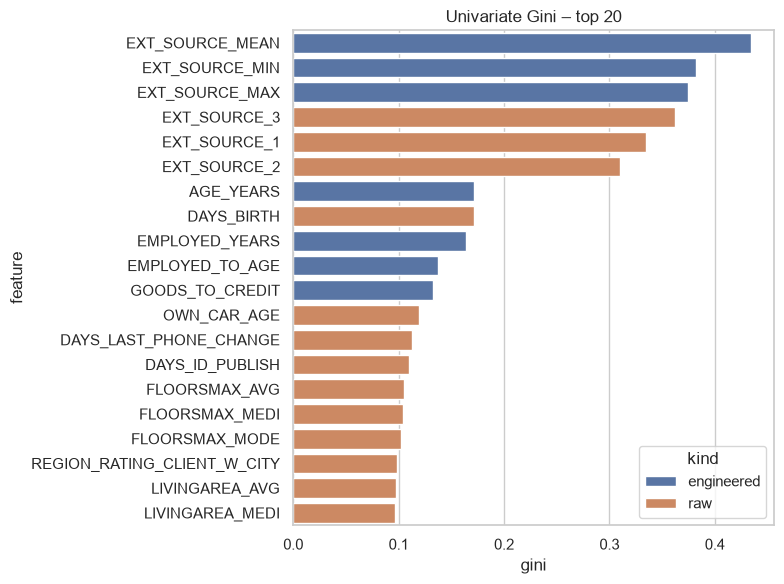

,feature,gini,direction,missing,kind
0,EXT_SOURCE_MEAN,0.4344,-,0.0005,engineered
1,EXT_SOURCE_MIN,0.3825,-,0.0005,engineered
2,EXT_SOURCE_MAX,0.3744,-,0.0005,engineered
3,AGE_YEARS,0.1715,-,0.0000,engineered
4,EMPLOYED_YEARS,0.1639,-,0.1796,engineered
5,EMPLOYED_TO_AGE,0.1369,-,0.1796,engineered
6,GOODS_TO_CREDIT,0.1329,-,0.0008,engineered
7,ANNUITY_TO_CREDIT,0.0665,+,0.0000,engineered
8,DAYS_EMPLOYED_ANOMALY,0.0660,-,0.0000,engineered
9,EXT_SOURCE_NULLS,0.0521,+,0.0000,engineered


In [3]:
fe = add_features(train)
eng = univariate_gini(fe, list(ENGINEERED_FEATURES)).assign(kind="engineered")
raw_cols = [c for c in train.select_dtypes("number").columns if c not in (TARGET, cfg["data"]["id_col"])]
raw = univariate_gini(train, raw_cols).head(15).assign(kind="raw")
both = pd.concat([eng, raw]).sort_values("gini", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(both, y="feature", x="gini", hue="kind", dodge=False, ax=ax); ax.set_title("Univariate Gini – top 20"); plt.tight_layout(); plt.show()
eng

## 2. Information value (IV) and monotonicity

IV on quantile bins (credit-scoring convention: <0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, >0.3 strong).

In [4]:
def woe_iv(df, col, bins=10):
    s = df[col]
    b = (s.astype(str) if s.nunique() <= bins else pd.qcut(s, bins, duplicates="drop").astype(str)).where(s.notna(), "Missing")
    t = df.groupby(b)[TARGET].agg(["sum", "size"]).rename(columns={"sum": "bad"})
    t["good"] = t["size"] - t["bad"]
    dist_b, dist_g = (t["bad"] / t["bad"].sum()).clip(1e-6), (t["good"] / t["good"].sum()).clip(1e-6)
    t["woe"] = np.log(dist_g / dist_b); t["default_rate"] = t["bad"] / t["size"]
    return t, float(((dist_g - dist_b) * t["woe"]).sum())

iv = pd.DataFrame([{"feature": c, "iv": woe_iv(fe, c)[1]} for c in list(ENGINEERED_FEATURES) + ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_CREDIT", "AMT_INCOME_TOTAL"]])
iv.sort_values("iv", ascending=False, ignore_index=True)

,feature,iv
0,EXT_SOURCE_MEAN,0.6141
1,EXT_SOURCE_MIN,0.4667
2,EXT_SOURCE_MAX,0.4484
3,EXT_SOURCE_3,0.3346
4,EXT_SOURCE_2,0.3005
5,EXT_SOURCE_1,0.1544
6,EMPLOYED_YEARS,0.1131
7,ANNUITY_TO_CREDIT,0.0925
8,EMPLOYED_TO_AGE,0.0906
9,AGE_YEARS,0.0897


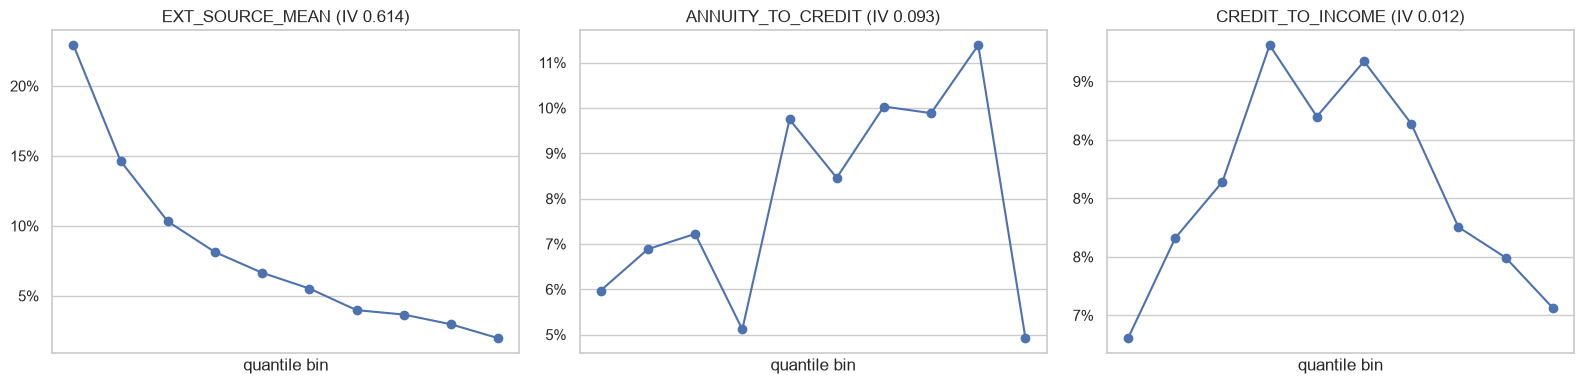

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["EXT_SOURCE_MEAN", "ANNUITY_TO_CREDIT", "CREDIT_TO_INCOME"]):
    t, v = woe_iv(fe, c)
    t = t.drop(index="Missing", errors="ignore")
    t["default_rate"].plot(ax=ax, marker="o"); ax.set(title=f"{c} (IV {v:.3f})", xlabel="quantile bin"); ax.set_xticks([])
    ax.yaxis.set_major_formatter("{x:.0%}")
plt.tight_layout(); plt.show()

`ANNUITY_TO_CREDIT` (repayment rate, roughly the inverse of the term) is **non-monotonic**. Tree models capture that, but a linear scorecard would need binning.

## 3. Ablation: does feature engineering help the model?

Same LightGBM settings on a 60k training sample, scored on the validation split, with and without `add_features`.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from lightgbm import LGBMClassifier
from credit_risk.features import build_preprocessor, split_column_types
from credit_risk.ingestion import sample_splits

s = sample_splits(splits, 60_000, cfg)
X, y = s.xy("train", cfg); Xv, yv = s.xy("val", cfg)
params = {**cfg["model"]["params"]["lightgbm"], "n_estimators": 400}

def fit_score(engineer: bool) -> float:
    if engineer:
        num, cat = split_column_types(X); step = FunctionTransformer(add_features, validate=False)
    else:
        cat = X.select_dtypes(include=["object", "string"]).columns.tolist(); num = [c for c in X if c not in cat]
        step = FunctionTransformer(validate=False)
    pipe = Pipeline([("features", step), ("preprocess", build_preprocessor(num, cat, scale=False)),
                     ("model", LGBMClassifier(**params))]).set_output(transform="pandas")
    pipe.fit(X, y)
    return roc_auc_score(yv, pipe.predict_proba(Xv)[:, 1])

res = pd.Series({"raw features only": fit_score(False), "raw + engineered": fit_score(True)}, name="validation AUC")
print(res.to_string()); print(f"Gini uplift: {2 * (res.iloc[1] - res.iloc[0]):+.4f}")

raw features only   0.7535
raw + engineered    0.7551
Gini uplift: +0.0033


## Conclusions

- Bureau-score aggregates (`EXT_SOURCE_MEAN/MIN/MAX`) are the strongest single features: `EXT_SOURCE_MEAN` beats every raw bureau score on Gini and IV.
- **Loan-structure** ratios carry signal: `GOODS_TO_CREDIT` (loan-to-value proxy) and `ANNUITY_TO_CREDIT` (repayment rate, non-monotonic). Classic **affordability** ratios (`CREDIT_TO_INCOME`, `ANNUITY_TO_INCOME`) are weak on this data, possibly because income is self-reported. They are kept because they are cheap and tree models down-weight them.
- Engineered features give a **modest** validation uplift on the same sample and settings (≈ +0.002 AUC). Most of the gain comes from the bureau-score aggregates.
- Features are chosen on **validation** data only. The test split is reserved for the final champion/challenger decision.

→ Next: `03_model_experiments.ipynb`